In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader

import torchvision
import torchvision.transforms as transforms
from PIL import Image


import numpy as np
import matplotlib.pyplot as plt

from google.colab import drive

from PIL import Image

import os
import numpy as np
import torch
import torch.nn as nn
import torchvision
from torchvision import datasets
import torchvision.utils as vutils
from torch.utils.data import Subset


try:
  import torchdiff
except ImportError:
  !pip install torchdiff


from torchdiff.sde import SchedulerSDE, ForwardSDE, ReverseSDE, TrainSDE, SampleSDE
from torchdiff.utils import TextEncoder, Metrics, snr_capped_loss, mse_loss, DiffusionNetwork


if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    print('GPU indisponible, CPU à la place.')
    DEVICE = torch.device("cpu")


#montage du drive
drive.mount('/content/drive')

SAVE_DIR = "/content/drive/MyDrive/fmnist_dataset" #répertoire de sauvegarde sur le drive
os.makedirs(SAVE_DIR, exist_ok=True) # créer le repértoire s'il n'existe pas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 281.0/281.0 kB 12.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.8/53.8 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 50.7 MB/s eta 0:00:00
Mounted at /content/drive


# Test de la méthode SGM sur FashionMNIST

## Génération de l'ensemble de données

In [ ]:
fmnist_train = torchvision.datasets.FashionMNIST(
    root = './data/FashionMNIST',
    train = True,
    download = True,
    transform = transforms.Compose([
        transforms.ToTensor(), transforms.Lambda(lambda x: x * 2.0 - 1.0)
    ])
)

fmnist_valid = torchvision.datasets.FashionMNIST(
    root = './data/FashionMNIST',
    train = False,
    download = True,
    transform = transforms.Compose([
        transforms.ToTensor(), transforms.Lambda(lambda x: x * 2.0 - 1.0)
    ])
)

labels_map = {
    0: "T-Shirt",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle Boot",
}

100%|██████████| 26.4M/26.4M [00:02<00:00, 11.8MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 211kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.93MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 14.0MB/s]


In [ ]:
class FMNISTText(torch.utils.data.Dataset):
    def __init__(self, dataset):
        self.dataset = dataset
        self.classes = labels_map

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        x, y = self.dataset[idx]
        text = self.classes[y]
        return x, text

In [ ]:
batch_size = 64
fmnist_train_loader = DataLoader(FMNISTText(fmnist_train), batch_size=batch_size)
fmnist_valid_loader = DataLoader(FMNISTText(fmnist_valid), batch_size=batch_size)

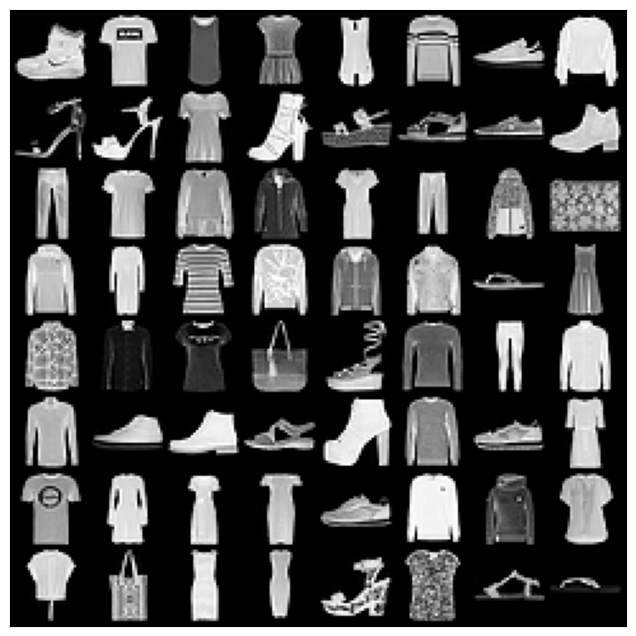

In [ ]:
def show_images(loader, grid_size = (8, 8)):
  loader_iter = iter(loader)
  images, labels = next(loader_iter)
  images = (images * 0.5) + 0.5
  images = images.clamp(0,1)
  img = torchvision.utils.make_grid(images)
  plt.figure(figsize=grid_size)
  plt.imshow(np.transpose(img, (1, 2, 0)))
  plt.xticks(())
  plt.yticks(())
  plt.show()


show_images(fmnist_train_loader)

## Entraînement et stockage du réseau prédisant le score

In [ ]:
# réseau de neurones utilisés (U-net) pour prévoir le score ou le bruit
diff_net = DiffusionNetwork(
    in_channels = 1,
    down_channels = [32, 64, 128, 256],
    mid_channels = [256, 256, 256],
    up_channels = [256, 128, 64, 32],
    down_sampling = [True, True, True],
    time_embed_dim = 256,
    y_embed_dim = 256,
    num_down_blocks = 2,
    num_mid_blocks =  2,
    num_up_blocks = 2,
    down_sampling_factor = 2,
    cont_time = True,
    use_flash_attention = True
).to(DEVICE)

# Text encoder pour génération conditionnelle (si désiré)
text_enc = TextEncoder(model_name="bert-base-uncased", output_dimension=256)


# Métriques d'évaluation (si désiré)
metrics = Metrics(device=DEVICE, fid=False, metrics=True, lpips_=False)

optim = torch.optim.AdamW(
    [p for p in diff_net.parameters()], lr=1e-4
)

# Paramètres pour décrire les SDE de diffusion

vs = SchedulerSDE("linear")
fwd = ForwardSDE(vs, 'vp', 'noise')
rev = ReverseSDE(vs, 'vp', 'noise')

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [ ]:
# Nombre de paramètres du modèle
print(sum(p.numel() for p in diff_net.parameters()))

11453249


In [ ]:
# Entrainement du score_net
def training(_fwd,_rev,_score_net,_optim,train_loader,valid_loader,nb_epochs,metrics=None,text_enc=None):
  trainer = TrainSDE(
    score_net = _score_net,
    fwd_sde = _fwd,
    rwd_sde = _rev,
    optim = _optim,
    loss_fn = mse_loss,
    cond_net = text_enc,
    train_loader = train_loader,
    val_loader = valid_loader,
    max_epochs = nb_epochs,
    device = DEVICE,
    grad_acc = 2,
    log_freq = 1,
    warmup_steps = 8000,
    metrics_ = metrics
  )
  return trainer()

# Sauvegarde du score_net et de l'optimiseur dans le fichier filepath
def save_model_optim(_score_net,_optim, filepath):
  torch.save({
    'model_state_dict': diff_net.state_dict(),
    'optimizer_state_dict': optim.state_dict()
   }, filepath)


In [ ]:
# À ne pas exécuter si a déjà été exécuté une fois

#Entrainement
losses = training(fwd,rev,diff_net,optim,fmnist_train_loader,fmnist_valid_loader,5,metrics=metrics,text_enc=None)

#Sauvegarde
checkpoint_path = f"{SAVE_DIR}/checkpoint.pth"
save_model_optim(diff_net,optim, checkpoint_path)

Epoch 1/5: 100%|██████████| 938/938 [01:49<00:00,  8.59it/s, Loss=0.0499]



Epoch: 1/5 | LR: 1.53e-05 | Train Loss: 0.0651

Model saved at epoch 1 with loss: 0.0651


Epoch 2/5: 100%|██████████| 938/938 [01:34<00:00,  9.90it/s, Loss=0.0761]



Epoch: 2/5 | LR: 2.06e-05 | Train Loss: 0.0660



Epoch 3/5: 100%|██████████| 938/938 [01:31<00:00, 10.28it/s, Loss=0.0407]



Epoch: 3/5 | LR: 2.58e-05 | Train Loss: 0.0656



Epoch 4/5: 100%|██████████| 938/938 [01:31<00:00, 10.30it/s, Loss=0.0885]



Epoch: 4/5 | LR: 3.11e-05 | Train Loss: 0.0666



Epoch 5/5: 100%|██████████| 938/938 [01:31<00:00, 10.28it/s, Loss=0.0652]



Epoch: 5/5 | LR: 3.64e-05 | Train Loss: 0.0661



## Génération d'images

In [ ]:
# Chargement du score_net stocké dans le fichier checkpoint_path
# (avec en plus les infos de l'optimiseur si reprise d'un training)

checkpoint_path = f"{SAVE_DIR}/checkpoint.pth"
checkpoint = torch.load(checkpoint_path)

diff_net = DiffusionNetwork(
    in_channels = 1,
    down_channels = [32, 64, 128, 256],
    mid_channels = [256, 256, 256],
    up_channels = [256, 128, 64, 32],
    down_sampling = [True, True, True],
    time_embed_dim = 256,
    y_embed_dim = 256,
    num_down_blocks = 2,
    num_mid_blocks =  2,
    num_up_blocks = 2,
    down_sampling_factor = 2,
    cont_time = True,
    use_flash_attention = True
).to(DEVICE)

diff_net.load_state_dict(checkpoint['model_state_dict'])
diff_net.eval()

# paramètres pour la génération

vs = SchedulerSDE("linear")
rev = ReverseSDE(vs, "vp", 'noise')


# Données à charger si réentrainement du score_net
#optim = torch.optim.AdamW(
#    [p for p in diff_net.parameters()], lr=1e-4
#)
#optim.load_state_dict(checkpoint['optimizer_state_dict'])

In [ ]:
# Générateur d'images sampler
sampler = SampleSDE(
    rwd_sde = rev ,
    score_net = diff_net ,
    img_size = (28, 28),
    batch_size = 64, # génère 64 images
    in_channels = 1, # un canal car seulement niveau de gris
    device=DEVICE,
    norm_range = (-1, 1)
)

In [ ]:
# Génération et stockage des images dans le répertoire gen_rep
gen_rep = f"{SAVE_DIR}/generated_samples"
imgs = sampler(num_steps = 1000, save_path = gen_rep) # 1000 pas pour générer les échantillons

Sampling: 100%|██████████| 1000/1000 [00:33<00:00, 30.07it/s]


In [ ]:
# pour visualiser les images générées
def visualize_png_images(directory, grid_size=(8, 8)):
    images = []
    num_images = grid_size[0] * grid_size[1]

    for i in range(1, num_images + 1):
        img_path = os.path.join(directory, f"img_{i}.png")
        if os.path.exists(img_path):
            img = Image.open(img_path).convert('L')
            img_tensor = torchvision.transforms.functional.to_tensor(img)
            images.append(img_tensor)

    if not images: return
    image_batch = torch.stack(images)
    grid = vutils.make_grid(image_batch, nrow=grid_size[0], padding=2)
    plt.figure(figsize=(10, 10))
    plt.axis("off")
    plt.imshow(grid.permute(1, 2, 0).cpu().numpy(), cmap='gray')
    plt.show()

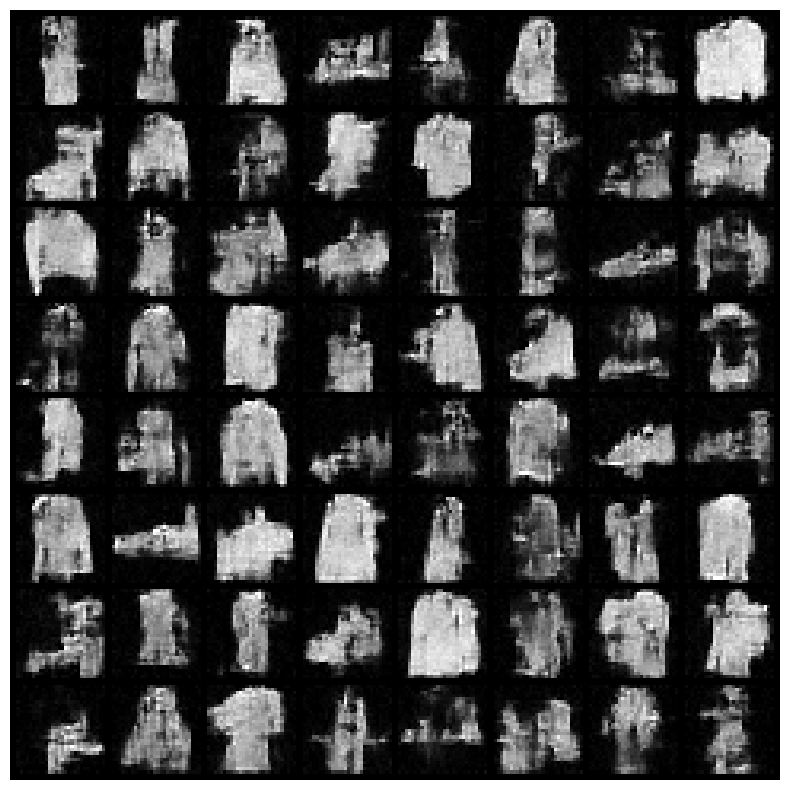

In [ ]:
visualize_png_images(gen_rep)